In [3]:
import numpy as np
import pandas as pd

In [4]:
fname_data = "../data/CM/Natural_CM.csv"
fname_gen = "../data/CM/Generated_CM.csv"

df_data = pd.read_csv(fname_data)
df_gen = pd.read_csv(fname_gen)

## Logistic regression

In [188]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from adabmDCA.fasta import encode_sequence, get_tokens

tokens = get_tokens("protein")
X_train = np.eye(21)[encode_sequence(df_data["sequence"].values, tokens=tokens)].reshape(len(df_data), -1)
y_train = df_data["label"].values
X_test = np.eye(21)[encode_sequence(df_gen["sequence"].values, tokens=tokens)].reshape(len(df_gen), -1)
y_test = df_gen["label"].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy on generated data: {accuracy * 100:.2f}%")

Accuracy on generated data: 78.36%


## Analyze the RBM model

In [208]:
import torch
from annadca import annaRBMcat
from annadca.dataset import annaDataset
from annadca.utils import get_eigenvalues_history
from annadca.plot import plot_PCA
from adabmDCA.fasta import get_tokens
from adabmDCA.stats import get_freq_single_point, get_freq_two_points, get_correlation_two_points
from adabmDCA.fasta import decode_sequence, encode_sequence
from adabmDCA.statmech import compute_energy
from adabmDCA.io import load_params


fname_data = "../data/CM/Natural_CM.csv"
fname_gen = "../data/CM/Generated_CM.csv"
fname_model = "../models/CM/RBM/CM_H1000_lr0.001_params.h5"
fname_chains = "../models/CM/RBM/CM_H1000_lr0.001_chains.fasta"
fname_params_bmDCA = "../models/CM/bmDCA/bmDCA_params.dat"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

# Import dataset
tokens = get_tokens("protein")
dataset = annaDataset(
    path_data=fname_data,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    device=device,
    dtype=dtype,
)

dataset_test = annaDataset(
    path_data=fname_gen,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    device=device,
    dtype=dtype,
)

data = dataset.data_one_hot
weights = dataset.weights.view(-1)
labels_data = dataset.to_label(dataset.labels_one_hot)

# Load the chains
rbm = annaRBMcat()
rbm.load(fname_model, device=device, dtype=dtype)
chains = rbm.load_chains(filename=fname_chains, alphabet=tokens, device=device, dtype=dtype)
labels_chains = dataset.to_label(chains["label"])

# load bmDCA parameters
bmDCA_params = load_params(fname_params_bmDCA, device=device, dtype=dtype, tokens=tokens)

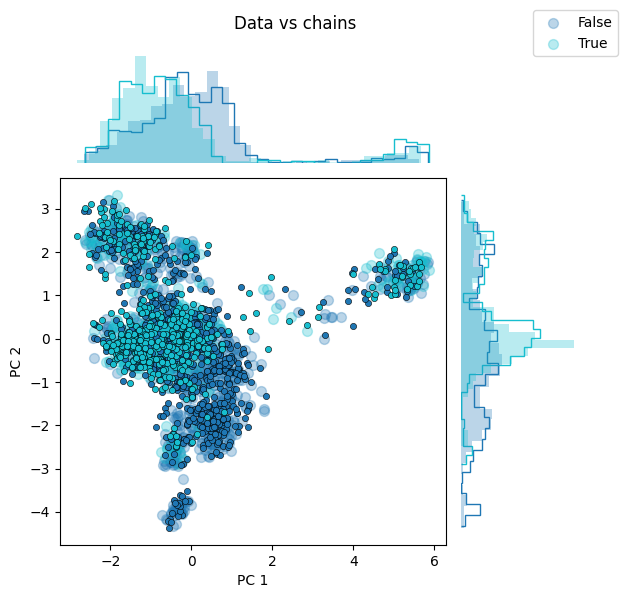

In [7]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Project data and chains on the same PCA space
pca = PCA(n_components=2)
data_proj = pca.fit_transform(data.reshape(len(data), -1).cpu().numpy())
chains_proj = pca.transform(chains["visible"].view(len(chains["visible"]), -1).cpu().numpy())

# Define the colors
unique_labels = np.unique(labels_data)
cmap = plt.get_cmap("tab10", len(unique_labels))
label_to_color = {label.item(): cmap(i) for i, label in enumerate(unique_labels)}

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=chains_proj,
    labels2=labels_chains,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs chains",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

### Sample unconditioned

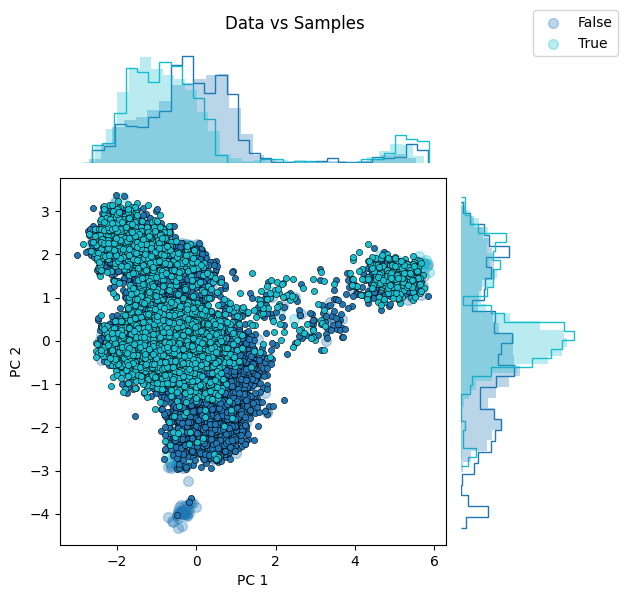

In [6]:
samples = rbm.sample(gibbs_steps=10000, num_samples=10000)
samples_proj = pca.transform(samples["visible"].view(len(samples["visible"]), -1).cpu().numpy())
samples_labels = dataset.to_label(samples["label"])

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=samples_proj,
    labels2=samples_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Samples",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

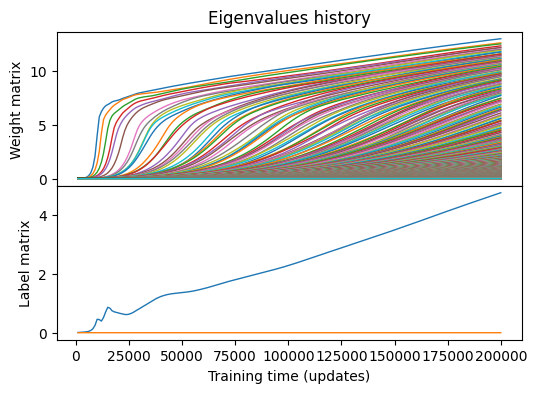

In [7]:
updates, eigenvalues = get_eigenvalues_history(fname_model, target_matrix="weight_matrix", device=device, dtype=dtype)
updates, eigenvalues_labels = get_eigenvalues_history(fname_model, target_matrix="label_matrix", device=device, dtype=dtype)

# Plot the eigenvalues history. first row is the weight matrix, second row is the label matrix.
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={'hspace': 0})
ax[0].plot(updates, eigenvalues, lw=1)
ax[1].plot(updates, eigenvalues_labels, lw=1)
ax[1].set_xlabel("Training time (updates)")
ax[0].set_ylabel("Weight matrix")
ax[1].set_ylabel("Label matrix")
ax[0].set_title("Eigenvalues history");

### Conditioned Sampling

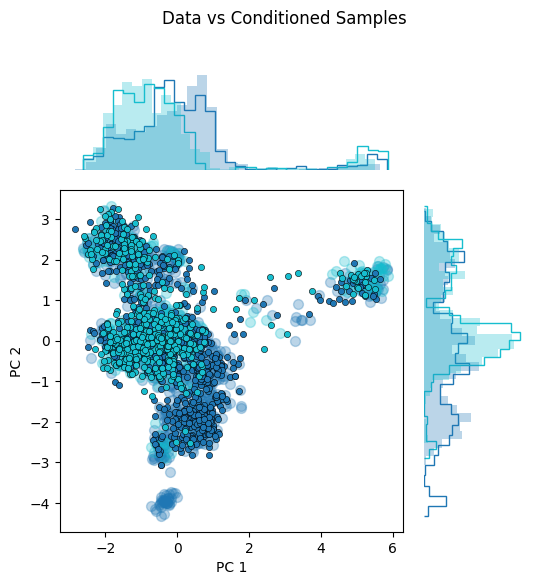

In [8]:
rbm.load(fname_model, device=device, dtype=dtype)
cond_chains = rbm.sample_conditioned(
    gibbs_steps=100000,
    targets=dataset.labels_one_hot,
)

cond_chains_proj = pca.transform(cond_chains["visible"].view(len(cond_chains["visible"]), -1).cpu().numpy())
cond_chains_labels = labels_data

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=cond_chains_proj,
    labels2=cond_chains_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Conditioned Samples",
    split_labels=True,
)

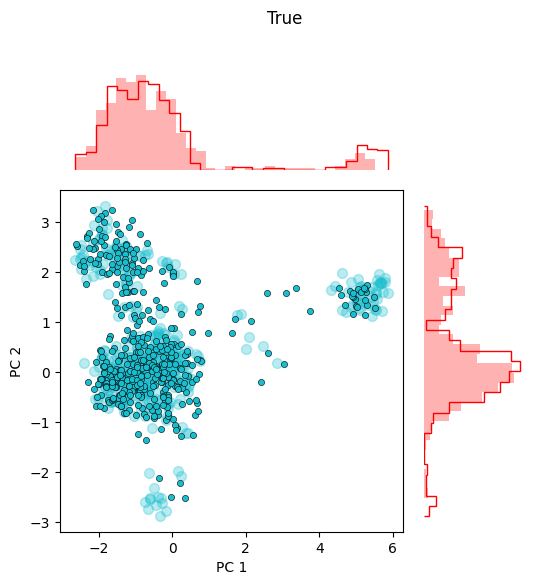

In [9]:
# Plot pca of conditioned chains and data but only one label
label_idx = 1
label = dataset.idx_to_label[label_idx]
mask_data = labels_data == label
mask_gen = cond_chains_labels == label
data_proj_label = data_proj[mask_data]
chains_proj_label = cond_chains_proj[mask_gen]

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj_label,
    labels1=labels_data[mask_data],
    data2=chains_proj_label,
    labels2=cond_chains_labels[mask_gen],
    label_to_color={label: cmap(label_idx)},
    dim1=0,
    dim2=1,
    title=label,
    split_labels=False,
)

In [10]:
# Train accuracy
predictions = rbm.predict_labels(visible=dataset.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Train accuracy: {accuracy}")

predictions = rbm.predict_labels(visible=dataset_test.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset_test.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Test accuracy: {accuracy}")

Train accuracy: 0.9203540086746216
Test accuracy: 0.7966101765632629


In [11]:
fi = get_freq_single_point(data=dataset.data_one_hot, weights=dataset.weights, pseudo_count=1e-8)
fij = get_freq_two_points(data=dataset.data_one_hot, weights=dataset.weights, pseudo_count=1e-8)
pi = get_freq_single_point(data=cond_chains["visible"], weights=None, pseudo_count=1e-8)
pij = get_freq_two_points(data=cond_chains["visible"], weights=None, pseudo_count=1e-8)

pearson, slope = get_correlation_two_points(fij, pij, fi, pi)
print(f"Pearson correlation: {pearson:.4f}, slope: {slope:.4f}")

Pearson correlation: 0.7986, slope: 0.7372


## Importance Sampling

In [69]:
from typing import Dict, Tuple

def importance_sampling(
    rbm: annaRBMcat,
    num_samples: int,
    wild_type: torch.Tensor,
    target_label_oh: torch.Tensor,
    ngibbs: int,
    is_strength: float,
    gen_strength: float = 1.0,
    label_strength: float = 1.0,
) -> Dict[str, torch.Tensor]:
    """Perform importance sampling with the RBM conditioned to a target label.

    Args:
        rbm (annaRBMbin): annaRBMbin instance.
        num_samples (int): Number of samples to generate.
        wild_type (torch.Tensor): Wild type sequence.
        target_label_oh (torch.Tensor): One-hot encoded target label.
        ngibbs (int): Number of Gibbs sampling steps.
        is_strength (float): Importance weight for the wild type.
        gen_strength (float, optional): Controls the relative importance of the generative Hamiltonian. Defaults to 1.0.
        label_strength (float, optional): Controls the relative importance of the label Hamiltonian. Defaults to 1.0.

    Returns:
        Dict[str, torch.Tensor]: Generated samples.
    """
    # replicate the wild type sequence
    samples = wild_type.unsqueeze(0).repeat(num_samples, 1, 1)
    
    # modify the visible bias for importance sampling
    rbm_mod = rbm.clone()

    # rescale the generative hamiltonian by gen_strength
    rbm_mod.params["weight_matrix"] *= gen_strength
    rbm_mod.params["vbias"] *= gen_strength
    rbm_mod.params["hbias"] *= gen_strength

    # bias on the wild type sites using importance sampling
    rbm_mod.params["vbias"] += is_strength * wild_type

    # rescale the label hamiltonian by label_strength
    rbm_mod.params["label_matrix"] *= label_strength
    rbm_mod.params["lbias"] *= label_strength

    # replicate the target label
    target_label_oh = target_label_oh.unsqueeze(0).repeat(num_samples, 1)
    samples = rbm_mod.sample_conditioned(
        gibbs_steps=ngibbs,
        visible=samples,
        targets=target_label_oh
    )
    
    return samples


def get_energy_contributions(
    rbm: annaRBMcat,
    samples: Dict[str, torch.Tensor],
    target_label_oh: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor]:
    # Generative energy
    Hgen = rbm.compute_energy_visibles(
        visible=samples["visible"],
    )
    # Label probability
    target_label_idx = target_label_oh.argmax(dim=-1)
    p_label = rbm.predict_labels(**samples)[:, target_label_idx]
    return Hgen, p_label

def get_distance_from_wt(
    wt: torch.Tensor,
    samples: Dict[str, torch.Tensor]
) -> torch.Tensor:
    L = samples["visible"].size(1)
    distances = L - torch.all((samples["visible"] == wt.unsqueeze(0)), dim=-1).sum(-1)
    return distances

In [9]:
# True -> Functional true
# False -> Functional false
functional_false_mask = dataset.to_label(dataset.labels_one_hot) == False
functional_false_sequences = dataset.data_one_hot[functional_false_mask]
target_label_oh = dataset.labels_one_hot[~functional_false_mask][0]

idx_wt = 11
wild_type = dataset.data_one_hot[idx_wt]

# visualize the wild type sequence in the pca space
wt_pca = pca.transform(wild_type.view(1, -1).cpu().numpy())

plt.rcParams.update({'font.size': 14,
                     'text.usetex': True})

import plotly.express as px

df_plot = pd.DataFrame({
    "PCA1": data_proj[:, 0],
    "PCA2": -data_proj[:, 1],
    "Label": labels_data,
    "Index": np.arange(len(labels_data))
})


fig_plotly = px.scatter(
    df_plot,
    x="PCA1",
    y="PCA2",
    color="Label",
    hover_data=["Index", "PCA1", "PCA2"],
    title="Natural Sequences (Interactive)",
    width=600,
    height=600
)

# plot also the wild type in the same figure
df_wild_type = pd.DataFrame({
    "PCA1": wt_pca[:, 0],
    "PCA2": -wt_pca[:, 1],
    "Label": "wild type",
    "Index": [999999],
})
fig_plotly.add_scatter(
    x=df_wild_type["PCA1"],
    y=df_wild_type["PCA2"],
    mode="markers",
    marker=dict(size=16, color="green", symbol="x", line=dict(width=2, color="black")),
    name="Wild Type (False)",
)
fig_plotly.show()

In [10]:
def get_energy_logreg(samples, target_label_oh):
    idx_label = target_label_oh.argmax().item()
    betas = logreg.coef_[idx_label]
    Hdiscr = - samples["visible"].cpu().numpy() @ betas
    return Hdiscr

def get_prob_logreg(samples, target_label_oh):
    idx_label = target_label_oh.argmax().item()
    p_label = logreg.predict_proba(samples["visible"].cpu().numpy().reshape(len(samples["visible"]), -1))[:, idx_label]
    return p_label

### Calibration

Target wild-type indices: 783, 1074, 145, 365, 960

In [67]:
idx_wt = 145
wild_type = dataset.data_one_hot[idx_wt]

# visualize the wild type sequence in the pca space
wt_pca = pca.transform(wild_type.view(1, -1).cpu().numpy())

In [197]:
def plot_summary(
    samples_pca: np.ndarray,
    wild_type_pca: np.ndarray,
    data_pca: np.ndarray,
    functional_false_mask: np.ndarray,
    idx_wt: int,
    distances: np.ndarray,
    energies: np.ndarray,
    p_rbm: np.ndarray,
    p_lr: np.ndarray,
    energy_wt: float,
    p_rbm_wt: float,
    p_lr_wt: float,
    title: str,
):
    fig, ax = plt.subplots(2, 2, figsize=(12, 10), dpi=100)
    ax = ax.flatten()

    idx = np.argsort(distances)[::-1]

    # Scatter plot PCA
    ax[0].scatter(data_pca[functional_false_mask, 0], -data_pca[functional_false_mask, 1], label='Functional False', alpha=0.5, color="red")
    ax[0].scatter(data_pca[~functional_false_mask, 0], -data_pca[~functional_false_mask, 1], label='Functional True', alpha=0.5, color="green")
    sc = ax[0].scatter(samples_pca[idx, 0], -samples_pca[idx, 1], c=distances[idx], cmap='Spectral', label='Samples')
    ax[0].scatter(wild_type_pca[:, 0], -wild_type_pca[:, 1], marker="X", s=200, c='deeppink', label='Wild Type (Func. False)', edgecolor='black')
    ax[0].legend()
    ax[0].set_xlabel("PCA 1")
    ax[0].set_ylabel("PCA 2")
    cbar = plt.colorbar(sc, ax=ax[0])
    cbar.set_label(r"Distance from Wild Type")
    
    # Histogram of distances
    ud, uc = np.unique(distances, return_counts=True)
    ax[1].bar(ud, uc, width=0.8, color='skyblue', alpha=0.7, edgecolor='black')
    ax[1].set_xlabel("Hamming Distance from Wild Type")
    
    # Scatter plot of Energy vs Probability
    ax[2].scatter(p_rbm[idx], energies[idx] - energy_wt, c=distances[idx], cmap="tab20b", label=f"Samples")
    ax[2].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
    ax[2].set_xlabel(r"$p_{\mathrm{rbm}}(\mathrm{FT})$")
    ax[2].set_title(f"Phase space")
    ax[2].scatter(p_rbm_wt, 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
    ax[2].set_xlim(-0.05, 1.05)
    ax[2].legend()
    
    # Scatter plot of Energy vs Probability (LogReg)
    sc = ax[3].scatter(p_lr[idx], energies[idx] - energy_wt, c=distances[idx], cmap="tab20b", label=f"Samples")
    ax[3].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
    ax[3].set_xlabel(r"$p_{\mathrm{lr}}(\mathrm{FT})$")
    ax[3].set_title(f"Phase space - LogReg")
    ax[3].scatter(p_lr_wt, 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
    ax[3].set_xlim(-0.05, 1.05)
    
    cbar = plt.colorbar(sc, ax=ax[3])
    cbar.set_label(r"Distance from WT")

    fig.suptitle(title, fontsize=16)
    fig.tight_layout()

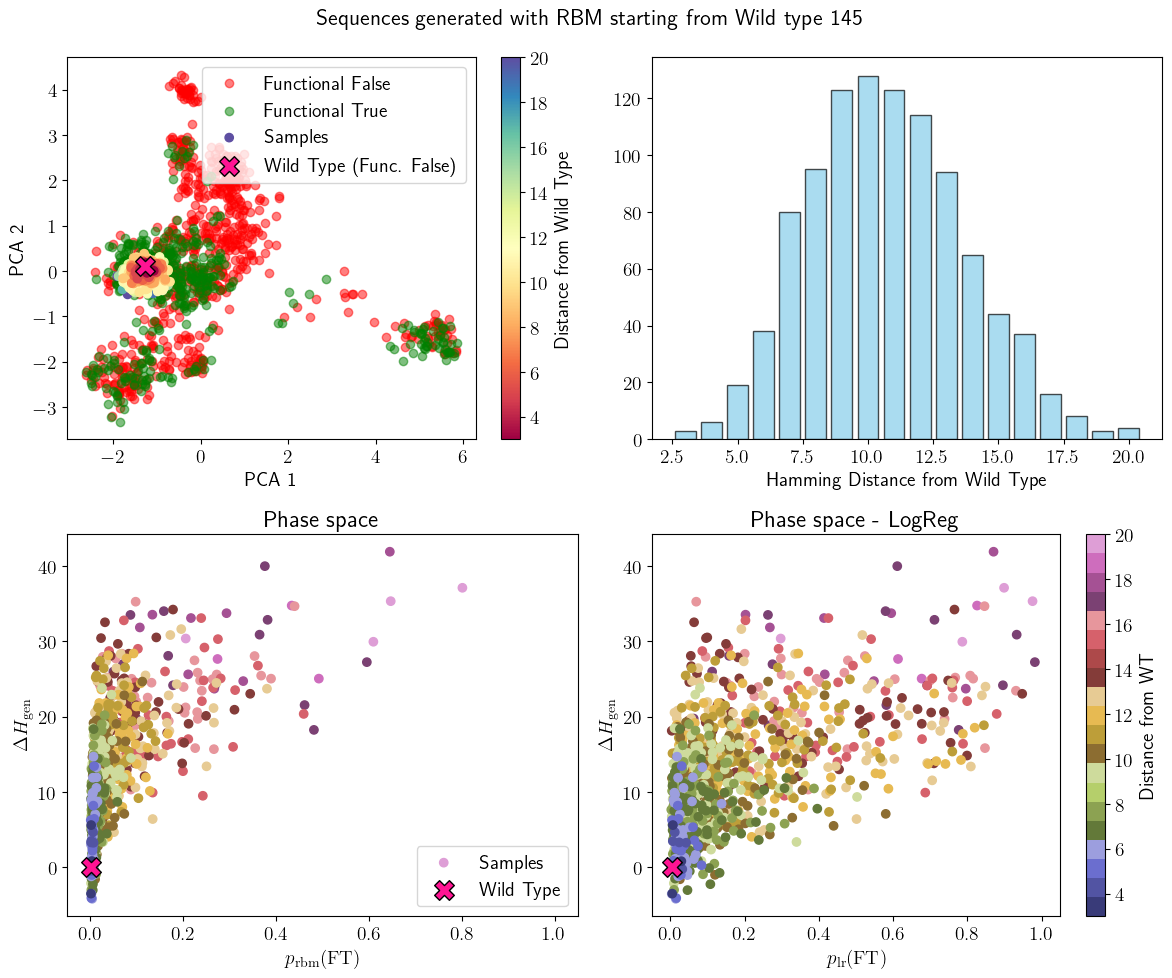

In [198]:
num_samples = 1000
ngibbs = 5000
is_strength = 2.2
gen_strength = 1.0
label_strength = 8.0

samples = importance_sampling(
    rbm=rbm,
    num_samples=num_samples,
    wild_type=wild_type,
    target_label_oh=target_label_oh,
    ngibbs=ngibbs,
    is_strength=is_strength,
    gen_strength=gen_strength,
    label_strength=label_strength,
)

samples_pca = pca.transform(samples["visible"].view(len(samples["visible"]), -1).cpu().numpy())
distances = get_distance_from_wt(
    wt=wild_type,
    samples=samples,
).cpu().numpy()
Hgen, p_rbm = get_energy_contributions(
    rbm=rbm,
    samples=samples,
    target_label_oh=target_label_oh,
)
p_lr = get_prob_logreg(samples, target_label_oh)
Hgen_wt, p_rbm_wt = get_energy_contributions(
    rbm=rbm,
    samples={"visible": wild_type.unsqueeze(0)},
    target_label_oh=target_label_oh,
)

p_lr_wt = get_prob_logreg({"visible": wild_type.unsqueeze(0)}, target_label_oh)

plot_summary(
    samples_pca=samples_pca,
    wild_type_pca=wt_pca,
    data_pca=data_proj,
    functional_false_mask=functional_false_mask,
    idx_wt=idx_wt,
    distances=distances,
    energies=Hgen.cpu().numpy(),
    p_rbm=p_rbm.cpu().numpy(),
    p_lr=p_lr,
    energy_wt=Hgen_wt.item(),
    p_rbm_wt=p_rbm_wt.item(),
    p_lr_wt=p_lr_wt.item(),
    title=f"Sequences generated with RBM starting from Wild type {idx_wt}",
)

In [ ]:
# Save Results

from adabmDCA.fasta import write_fasta

headers = [f"gen_{i}" for i in range(num_samples)]
write_fasta(
    fname=f"../generated/CM/Seq_gen_WT{idx_wt}_RBM_gen_strength{gen_strength}_label_strength8.0_is_strength{is_strength}.faa",
    headers=headers,
    sequences=samples["visible"].argmax(-1).cpu().numpy(),
    numeric_input=True,
)

Iterate the previous plot for many values of the importance weight

In [199]:
num_samples = 1000
ngibbs = 5000
gen_strength = 1.0
label_strength = 1.0

is_strength_list = 3 * np.append(np.array([0.]), np.logspace(-3, 0, 10))

fname = f"../generated/CM/CM_importance_sampling_WT{idx_wt}_gen_strength{gen_strength}_label_strength{label_strength}_ngibbs{ngibbs}.csv"
is_strength_records = []
p_rbm_records, p_lr_records, Hgen_records, distance_records, sample_records = [], [], [], [], []

for is_strength in is_strength_list:
    print(f"Importance weight: {is_strength:.4f}")
    samples = importance_sampling(
        rbm=rbm,
        num_samples=num_samples,
        wild_type=wild_type,
        target_label_oh=target_label_oh,
        ngibbs=ngibbs,
        is_strength=is_strength,
        gen_strength=gen_strength,
        label_strength=label_strength,
    )
    
    distances = get_distance_from_wt(
        wt=wild_type,
        samples=samples,
    )
    
    Hgen, p_rbm = get_energy_contributions(
        rbm=rbm,
        samples=samples,
        target_label_oh=target_label_oh,
    )
    p_lr = get_prob_logreg(samples, target_label_oh)
    
    # decode sequences
    samples_dec = list(decode_sequence(samples["visible"].argmax(dim=-1).tolist(), tokens=tokens))
    sample_records.extend(samples_dec)
    distance_records.extend(distances.tolist())
    Hgen_records.extend(Hgen.tolist())
    p_rbm_records.extend(p_rbm.tolist())
    p_lr_records.extend(p_lr.tolist())
    is_strength_records.extend([is_strength] * len(samples["visible"]))

# store results in a dataframe
df_results = pd.DataFrame({
    "Sample": sample_records,
    "Distance_from_WT": distance_records,
    "Hgen": Hgen_records,
    "p_rbm": p_rbm_records,
    "p_lr": p_lr_records,
    "Importance_strength": is_strength_records,
})
df_results.to_csv(fname, index=False)

Importance weight: 0.0000
Importance weight: 0.0030
Importance weight: 0.0065
Importance weight: 0.0139
Importance weight: 0.0300
Importance weight: 0.0646
Importance weight: 0.1392
Importance weight: 0.3000
Importance weight: 0.6463
Importance weight: 1.3925
Importance weight: 3.0000


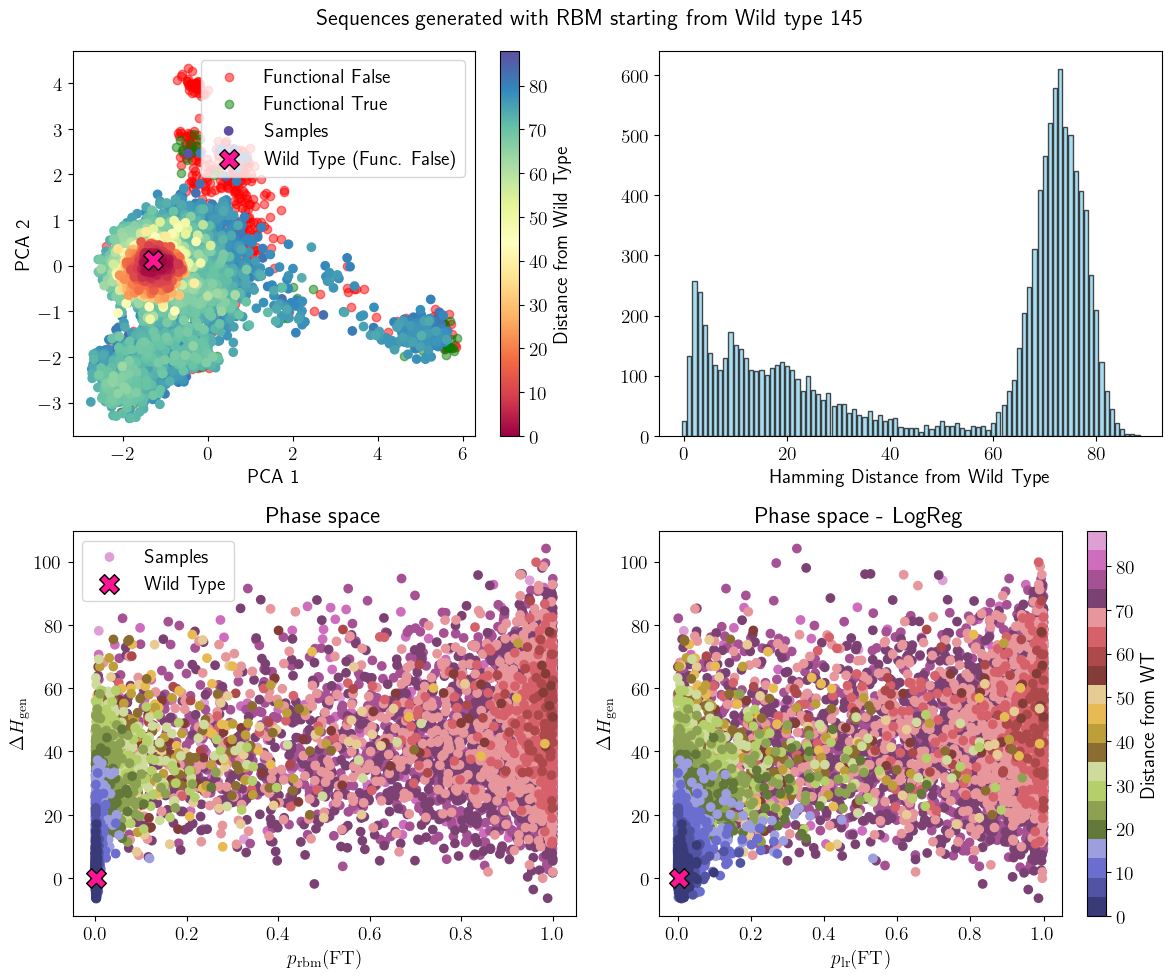

In [200]:
# import data from CSV
df_results = pd.read_csv(fname)

# pca of the samples
samples_enc = np.eye(len(tokens))[encode_sequence(df_results["Sample"].values, tokens=tokens)]
samples_pca = pca.transform(samples_enc.reshape(len(samples_enc), -1))

plot_summary(
    samples_pca=samples_pca,
    wild_type_pca=wt_pca,
    data_pca=data_proj,
    functional_false_mask=functional_false_mask,
    idx_wt=idx_wt,
    distances=df_results["Distance_from_WT"].values,
    energies=df_results["Hgen"].values,
    p_rbm=df_results["p_rbm"].values,
    p_lr=df_results["p_lr"].values,
    energy_wt=Hgen_wt.item(),
    p_rbm_wt=p_rbm_wt.item(),
    p_lr_wt=p_lr_wt.item(),
    title=f"Sequences generated with RBM starting from Wild type {idx_wt}",
)

### Test generated sequences

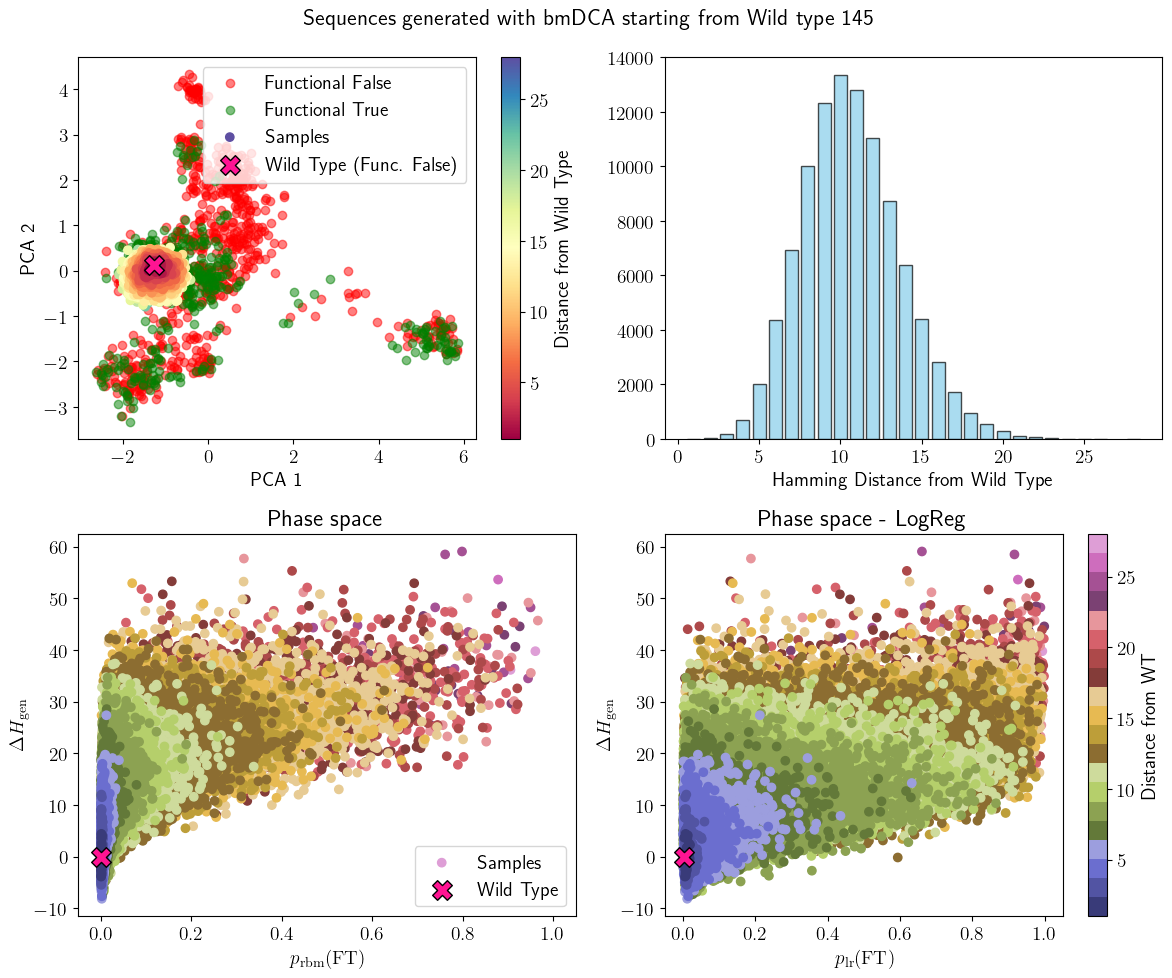

In [223]:
from adabmDCA.fasta import import_from_fasta

path_fasta = "../generated/CM/Seq_gen_WT145_RBM_gen_strength1.0_label_strength8.0_is_strength2.2.faa"
#path_fasta = "../generated/CM/Seq_gen_WT145_bmDCA_gen_strength1.0_label_strength1.0_is_strength3.0.faa"
_, seqs = import_from_fasta(path_fasta, tokens=tokens)
seqs_oh = torch.nn.functional.one_hot(torch.tensor(seqs), num_classes=len(tokens)).to(device=device, dtype=dtype)

H_rbm, p_rbm = get_energy_contributions(
    rbm=rbm,
    samples={"visible": seqs_oh},
    target_label_oh=target_label_oh
)
H_bm = compute_energy(seqs_oh, bmDCA_params).cpu().numpy()
H_rbm_wt = rbm.compute_energy_visibles(wild_type.unsqueeze(0))
H_bm_wt = compute_energy(wild_type.unsqueeze(0), bmDCA_params).cpu().numpy()

H_rbm = H_rbm.cpu().numpy()
p_rbm = p_rbm.cpu().numpy()
p_lr = get_prob_logreg({"visible": seqs_oh}, target_label_oh)
seqs_pca = pca.transform(seqs_oh.view(len(seqs_oh), -1).cpu().numpy())
distances = get_distance_from_wt(wild_type, {"visible": seqs_oh}).cpu().numpy()

plot_summary(
    samples_pca=seqs_pca,
    wild_type_pca=wt_pca,
    data_pca=data_proj,
    functional_false_mask=functional_false_mask,
    idx_wt=idx_wt,
    distances=distances,
    energies=H_rbm,
    p_rbm=p_rbm,
    p_lr=p_lr,
    energy_wt=Hgen_wt.item(),
    p_rbm_wt=p_rbm_wt.item(),
    p_lr_wt=p_lr_wt.item(),
    title=f"Sequences generated with bmDCA starting from Wild type {idx_wt}",
)

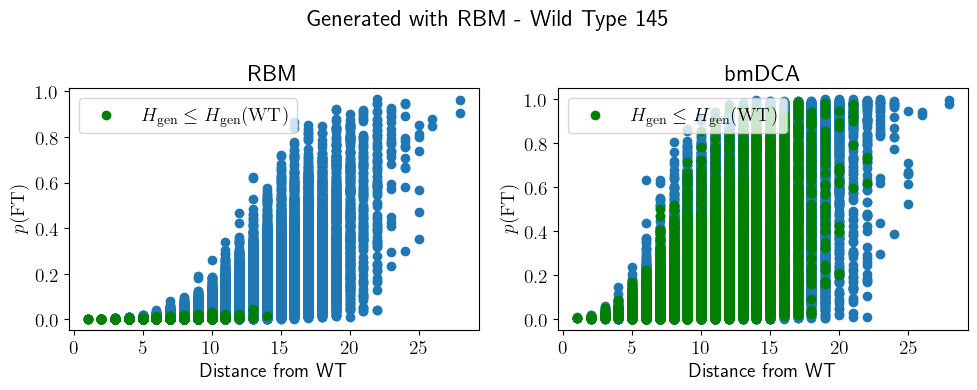

In [224]:
def plot_parenzio(
    ax: plt.Axes,
    distances: np.ndarray,
    probs: np.ndarray,
    energies: np.ndarray,
    energy_wt: float,
    title: str,
):
    mask = energies <= energy_wt
    ax.scatter(distances, probs)
    ax.scatter(distances[mask], probs[mask], label=r"$H_{\mathrm{gen}} \leq H_{\mathrm{gen}}(\mathrm{WT})$", color="green")
    ax.set_xlabel("Distance from WT")
    ax.set_ylabel(r"$p(\mathrm{FT})$")
    ax.set_title(title)
    ax.legend()
    return ax

fig, ax = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
ax[0] = plot_parenzio(
    ax=ax[0],
    distances=distances,
    probs=p_rbm,
    energies=H_rbm,
    energy_wt=H_rbm_wt.item(),
    title=f"RBM"
)

ax[1] = plot_parenzio(
    ax=ax[1],
    distances=distances,
    probs=p_lr,
    energies=H_bm,
    energy_wt=H_bm_wt.item(),
    title=f"bmDCA"
)
fig.suptitle(f"Generated with RBM - Wild Type {idx_wt}");
fig.tight_layout()

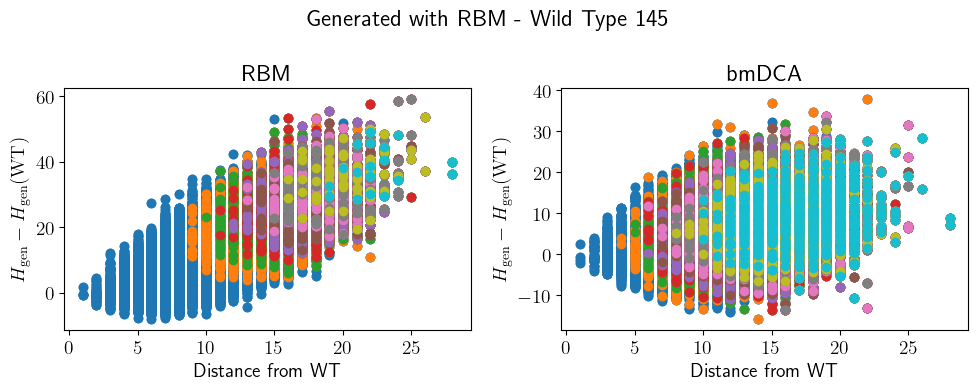

In [228]:
def plot_parenzio2(
    ax: plt.Axes,
    distances: np.ndarray,
    probs: np.ndarray,
    energies: np.ndarray,
    energy_wt: float,
    title: str,
):
    prob_ths = np.arange(0.0, 1.0, 0.1)
    cmap = plt.get_cmap("tab10")
    ax.scatter(distances, energies - energy_wt)
    for th in prob_ths:
        mask = probs >= th
        ax.scatter(distances[mask], (energies - energy_wt)[mask], label=f"$p \geq {th}$", color=cmap(int(th*10)))
    ax.set_xlabel("Distance from WT")
    ax.set_ylabel(r"$H_{\mathrm{gen}} - H_{\mathrm{gen}}(\mathrm{WT})$")
    ax.set_title(title)
    #ax.legend()
    return ax

fig, ax = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
ax[0] = plot_parenzio2(
    ax=ax[0],
    distances=distances,
    probs=p_rbm,
    energies=H_rbm,
    energy_wt=H_rbm_wt.item(),
    title=f"RBM"
)

ax[1] = plot_parenzio2(
    ax=ax[1],
    distances=distances,
    probs=p_lr,
    energies=H_bm,
    energy_wt=H_bm_wt.item(),
    title=f"bmDCA"
)
fig.suptitle(f"Generated with RBM - Wild Type {idx_wt}");
fig.tight_layout()

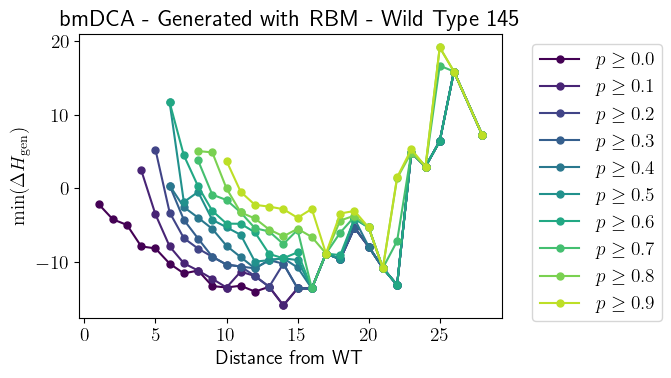

In [249]:
def plot_parenzio3(
    ax: plt.Axes,
    distances: np.ndarray,
    probs: np.ndarray,
    energies: np.ndarray,
    energy_wt: float,
    title: str,
):
    prob_ths = np.arange(0.0, 1.0, 0.1)
    cmap = plt.get_cmap("viridis")
    unique_distances = np.unique(distances)
    for th in prob_ths:
        mask = probs >= th
        dE_select = (energies - energy_wt)[mask]
        distances_sel = distances[mask]
        dE, d = [], []
        for ud in unique_distances:
            mask2 = distances_sel == ud
            if mask2.any():
                dE.append(dE_select[mask2].min())
                d.append(ud)
        ax.plot(d, dE, "-o", label=f"$p \geq {th:.1f}$", color=cmap(th), markersize=5)

    ax.set_xlabel("Distance from WT")
    ax.set_ylabel(r"$\min(\Delta H_{\mathrm{gen}})$")
    ax.set_title(title)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    return ax

fig, ax = plt.subplots(1, 1, figsize=(7, 4), dpi=100)
ax = plot_parenzio3(
    ax=ax,
    distances=distances,
    probs=p_lr,
    energies=H_bm,
    energy_wt=H_bm_wt.item(),
    title=f"bmDCA - Generated with RBM - Wild Type {idx_wt}"
)
fig.tight_layout()

### Compare bmDCA and RBM

In [166]:
fname_seqs = "../generated/CM/Seq_gen_WT145_bmDCA_gen_strength1.0_label_strength1.0_is_strength3.0.faa"
#fname_seqs = "../generated/CM/Seq_gen_WT145_RBM_gen_strength1.0_label_strength8.0_is_strength2.2.faa"
fname_params_bmDCA = "../models/CM/bmDCA/bmDCA_params.dat"
fname_params_RBM = "../models/CM/RBM/CM_H1000_lr0.001_params.h5"

rbm = annaRBMcat()
rbm.load(fname_params_RBM, device=device, dtype=dtype)
params_bm = load_params(fname_params_bmDCA, tokens=tokens, device=device, dtype=dtype)
_, seqs = import_from_fasta(fname_seqs, tokens=tokens)
seqs = torch.tensor(seqs, device=device, dtype=torch.int64)
seqs_oh = torch.nn.functional.one_hot(seqs, num_classes=len(tokens)).to(device=device, dtype=dtype)

energy_bm = compute_energy(seqs_oh, params_bm).cpu().numpy()
energy_rbm = rbm.compute_energy_visibles(visible=seqs_oh).cpu().numpy()

energy_rbm_wt = rbm.compute_energy_visibles(visible=wild_type.unsqueeze(0)).cpu().item()
energy_bm_wt = compute_energy(wild_type.unsqueeze(0), params_bm).cpu().item()

delta_energy_bm = energy_bm - energy_bm_wt
delta_energy_rbm = energy_rbm - energy_rbm_wt
# normalize the delta energies
prob_ratio_bm = np.exp(-delta_energy_bm)
prob_ratio_rbm = np.exp(-delta_energy_rbm)

probs_lr = get_prob_logreg({"visible": seqs_oh}, target_label_oh)
probs_rbm = rbm.predict_labels(visible=seqs_oh).cpu().numpy()[:, target_label_oh.argmax().item()]

distances = get_distance_from_wt(wild_type, {"visible": seqs_oh}).cpu().numpy()

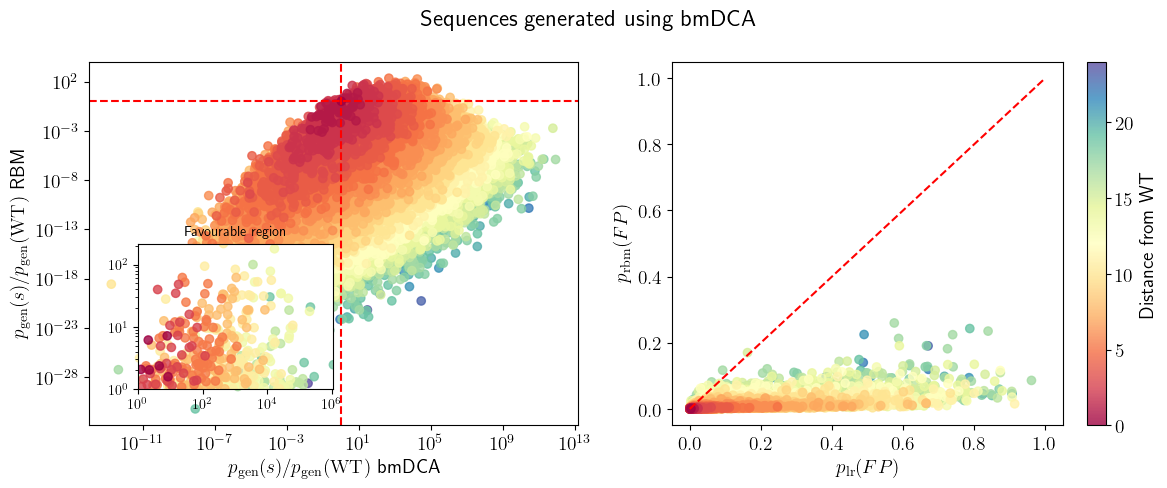

In [156]:
idx = np.argsort(distances)[::-1]

fig, ax = plt.subplots(1, 2, figsize=(12, 5), dpi=100)
ax[0].scatter(prob_ratio_bm[idx], prob_ratio_rbm[idx], alpha=0.8, c=distances[idx], cmap='Spectral')
x = np.linspace(min(prob_ratio_bm), max(prob_ratio_bm), 100)
ax[0].axvline(x=1, color='red', linestyle='--')
ax[0].axhline(y=1, color='red', linestyle='--')
ax[0].set_xlabel(r"$p_{\mathrm{gen}}(s) / p_{\mathrm{gen}}(\mathrm{WT})$ bmDCA")
ax[0].set_ylabel(r"$p_{\mathrm{gen}}(s) / p_{\mathrm{gen}}(\mathrm{WT})$ RBM")
ax[0].set_xscale('log')
ax[0].set_yscale('log')

# Inset axis in the bottom-left, with ticks included
inset_ax = ax[0].inset_axes([0.1, 0.1, 0.4, 0.4])
mask = (prob_ratio_bm[idx] > 1) & (prob_ratio_rbm[idx] > 1)
inset_ax.scatter(prob_ratio_bm[idx][mask], prob_ratio_rbm[idx][mask], alpha=0.8, c=distances[idx][mask], cmap='Spectral')
inset_ax.set_xscale('log')
inset_ax.set_yscale('log')
inset_ax.set_xlim(1, prob_ratio_bm[idx][mask].max())
inset_ax.set_ylim(1, prob_ratio_rbm[idx][mask].max())
inset_ax.set_title("Favourable region", fontsize=10)
# Ticks included
inset_ax.tick_params(axis='both', which='both', labelsize=10)

sp = ax[1].scatter(probs_lr[idx], probs_rbm[idx], alpha=0.8, c=distances[idx], cmap='Spectral')
x = np.linspace(0, 1, 100)
ax[1].plot(x, x, color='red', linestyle='--')
ax[1].set_xlabel(r"$p_{\mathrm{lr}}(FP)$")
ax[1].set_ylabel(r"$p_{\mathrm{rbm}}(FP)$")
fig.colorbar(sp, ax=ax[1], orientation='vertical', label='Distance from WT')
fig.suptitle("Sequences generated using bmDCA")

fig.tight_layout();

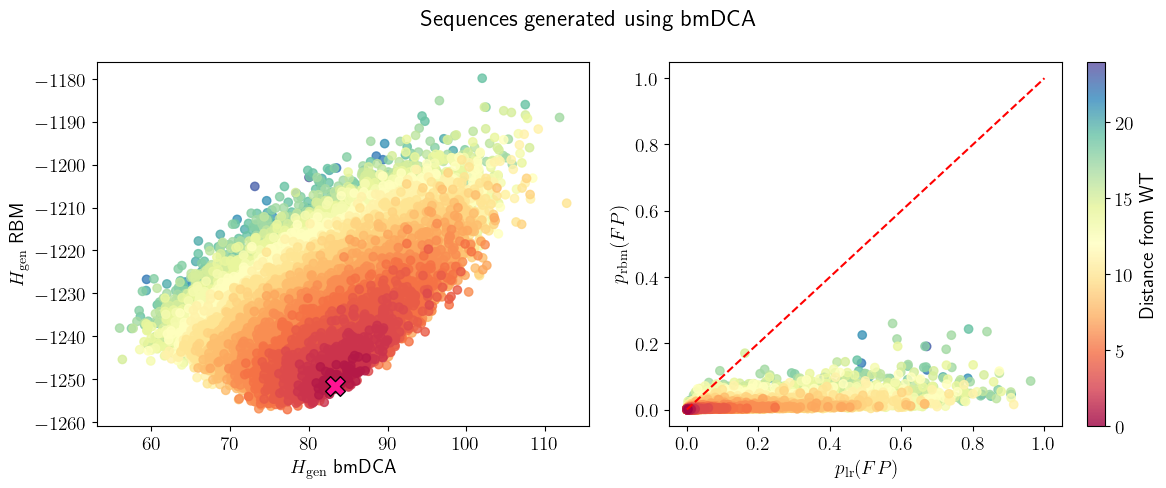

In [167]:
idx = np.argsort(distances)[::-1]

fig, ax = plt.subplots(1, 2, figsize=(12, 5), dpi=100)
ax[0].scatter(energy_bm[idx], energy_rbm[idx], alpha=0.8, c=distances[idx], cmap='Spectral')
# plt wt energy
ax[0].scatter(energy_bm_wt, energy_rbm_wt, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
ax[0].set_xlabel(r"$H_{\mathrm{gen}}$ bmDCA")
ax[0].set_ylabel(r"$H_{\mathrm{gen}}$ RBM")

sp = ax[1].scatter(probs_lr[idx], probs_rbm[idx], alpha=0.8, c=distances[idx], cmap='Spectral')
x = np.linspace(0, 1, 100)
ax[1].plot(x, x, color='red', linestyle='--')
ax[1].set_xlabel(r"$p_{\mathrm{lr}}(FP)$")
ax[1].set_ylabel(r"$p_{\mathrm{rbm}}(FP)$")
fig.colorbar(sp, ax=ax[1], orientation='vertical', label='Distance from WT')
fig.suptitle("Sequences generated using bmDCA")

fig.tight_layout();

### Analysis of the tested sequences generated in Calvanese et al

In [171]:
fname_seqs = "../data/CM/P1_sample_CM.faa"

headers, seqs = import_from_fasta(fname_seqs, tokens=tokens)
seqs = torch.tensor(seqs, device=device, dtype=torch.int64)
seqs_oh = torch.nn.functional.one_hot(seqs, num_classes=len(tokens)).to(device=device, dtype=dtype)
labels = [s.split(" ")[1] for s in headers]
map_labels = {
    "functional_true": "Functional True",
    "functional_false": "Functional False",
}
labels = np.array([map_labels[l] for l in labels])

energy_bm = compute_energy(seqs_oh, params_bm).cpu().numpy()
energy_rbm = rbm.compute_energy_visibles(visible=seqs_oh).cpu().numpy()
energy_bm_data = compute_energy(dataset.data_one_hot, params_bm).cpu().numpy()
energy_rbm_data = rbm.compute_energy_visibles(visible=dataset.data_one_hot).cpu().numpy()

probs_lr = get_prob_logreg({"visible": seqs_oh}, target_label_oh)
probs_rbm = rbm.predict_labels(visible=seqs_oh).cpu().numpy()[:, target_label_oh.argmax().item()]

# correlation cofficient of the energies
corr_coef = np.corrcoef(energy_bm, energy_rbm)[0, 1]
# correlation coefficient of the probabilities
corr_coef_probs = np.corrcoef(probs_lr, probs_rbm)[0, 1]

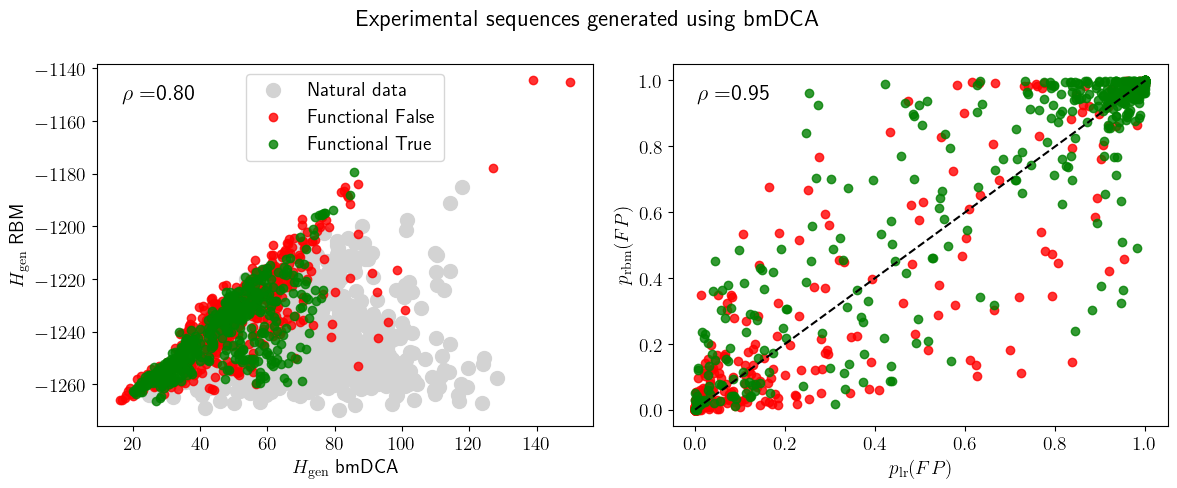

In [176]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), dpi=100)
color_map = {
    "Functional True": "green",
    "Functional False": "red",
}

ax[0].scatter(energy_bm_data, energy_rbm_data, label='Natural data', color='lightgray', s=100)
for l in np.unique(labels):
    mask = labels == l
    ax[0].scatter(energy_bm[mask], energy_rbm[mask], alpha=0.8, label=l, color=color_map[l])
    ax[1].scatter(probs_lr[mask], probs_rbm[mask], alpha=0.8, label=l, color=color_map[l])

ax[0].annotate(r"$\rho = $" + f"{corr_coef:.2f}", xy=(0.05, 0.9), xycoords="axes fraction", fontsize=16)
ax[1].annotate(r"$\rho = $" + f"{corr_coef_probs:.2f}", xy=(0.05, 0.9), xycoords="axes fraction", fontsize=16)
ax[0].set_xlabel(r"$H_{\mathrm{gen}}$ bmDCA")
ax[0].set_ylabel(r"$H_{\mathrm{gen}}$ RBM")
x = np.linspace(0, 1, 100)
ax[1].plot(x, x, color='black', linestyle='--')
ax[1].set_xlabel(r"$p_{\mathrm{lr}}(FP)$")
ax[1].set_ylabel(r"$p_{\mathrm{rbm}}(FP)$")
ax[0].legend()
fig.suptitle("Experimental sequences generated using bmDCA")

fig.tight_layout();

### Logo plot patterns

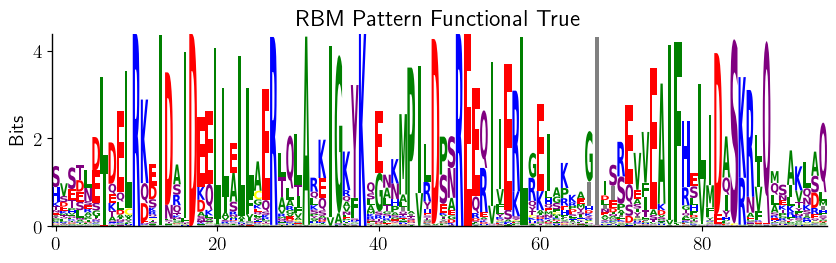

In [10]:
import pandas as pd
import logomaker

def plot_logo(prob, tokens, title=""):
    L, q = prob.shape
    aa_color_scheme = {
        'A': 'green',  # hydrophobic
        'C': 'yellow',
        'D': 'red',    # acidic
        'E': 'red',
        'F': 'green',
        'G': 'green',
        'H': 'blue',   # basic
        'I': 'green',
        'K': 'blue',
        'L': 'green',
        'M': 'green',
        'N': 'purple', # polar
        'P': 'green',
        'Q': 'purple',
        'R': 'blue',
        'S': 'purple',
        'T': 'purple',
        'V': 'green',
        'W': 'green',
        'Y': 'purple',
        '-': 'gray'    # gap
    }
    # Compute information content (bits)
    entropy = -(prob * np.log2(prob + 1e-9)).sum(axis=1)   # H_i
    R = np.log2(q) - entropy                         # R_i
    # Scale each probability by R_i
    IC = prob * R[:, np.newaxis]
    df = pd.DataFrame(IC, columns=list(tokens))
    logo = logomaker.Logo(
        df,
        shade_below=.5,
        fade_below=.5,
        color_scheme=aa_color_scheme,
    )
    logo.style_spines(visible=False)
    logo.style_spines(spines=['left', 'bottom'], visible=True)
    logo.ax.set_ylabel("Bits")
    logo.ax.set_title(title)
    plt.show()

# Should I put the vbias or not?
pattern_rbm = torch.softmax(rbm.get_pattern(dataset.label_to_idx[True]) + rbm.params["vbias"], dim=1)
plot_logo(pattern_rbm.cpu().numpy(), tokens, title="RBM Pattern Functional True")

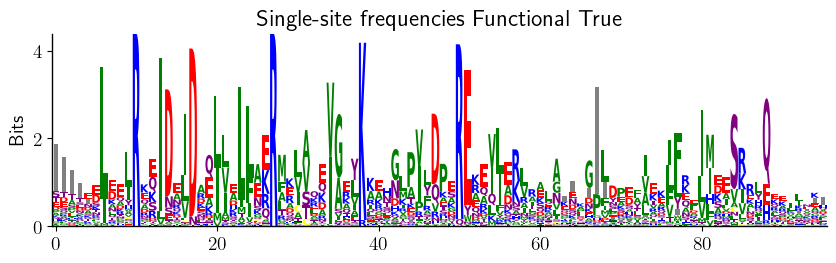

In [13]:
fi_functional_true = get_freq_single_point(
    data=dataset.data_one_hot[dataset.to_label(dataset.labels_one_hot) == True],
    weights=dataset.weights[dataset.to_label(dataset.labels_one_hot) == True]
)

plot_logo(fi_functional_true.cpu().numpy(), tokens, title="Single-site frequencies Functional True")

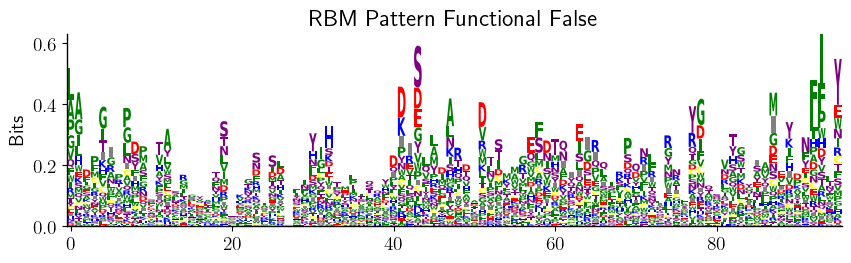

In [14]:
pattern_rbm = torch.softmax(rbm.get_pattern(dataset.label_to_idx[False]), dim=1)
plot_logo(pattern_rbm.cpu().numpy(), tokens, title="RBM Pattern Functional False")

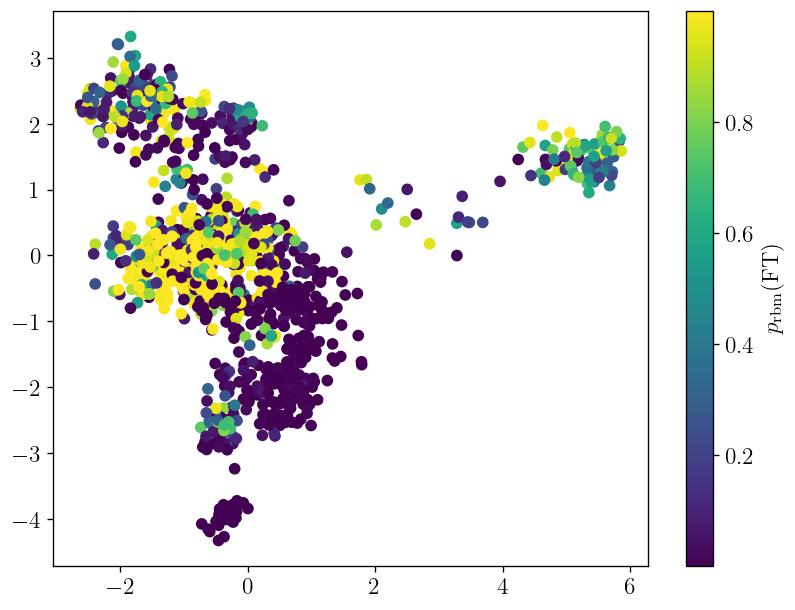

In [52]:
probs_data = rbm.predict_labels(visible=dataset.data_one_hot)[:, dataset.label_to_idx[True]]

fig = plt.figure(figsize=(8,6), dpi=120)
sp = plt.scatter(data_proj[:, 0], data_proj[:, 1], c=probs_data.cpu().numpy(), cmap='viridis', alpha=1.0)
# add colorbar
cbar = plt.colorbar(sp)
cbar.set_label(r"$p_{\mathrm{rbm}}(\mathrm{FT})$")